# PathSnap | From raw GPS to a reconstructed route

**Question.** Which directed road carried the vehicle at each GPS observation, and how well does the resulting sequence recover the supplied route?

**Run from a fresh kernel.** Place this notebook beside `Student folder/` (containing `train/` and `student_test/`), or inside that folder beside the two partitions. Choose **Restart Kernel and Run All Cells**. All algorithms are defined below. The only external inputs are the supplied trip files and the Python packages. For reproducing the original experiment, use Python 3.14, NumPy 2.5.4, SciPy 1.18.1, scikit-learn 1.9.1 and joblib 1.6.0. Install pandas, matplotlib and JupyterLab in the same environment. From an activated environment, a complete install command is:

```bash
python -m pip install numpy==2.5.4 scipy==1.18.1 scikit-learn==1.9.1 joblib==1.6.0 pandas matplotlib jupyterlab
```

**Files to inspect for marking.** `cleaned_data/train/` and `cleaned_data/student_test/` each get a readable CSV per trip. `cleaned_data/inventory.csv` records the checks, dimensions and candidate misses. `notebook_run/` holds the fold assignments, experiment tables, tuning history, freshly fitted model, decoder settings and route results. A rerun regenerates these outputs.

Follow one real training trip through sections 2–4, inspect the exported training rows in section 5, then compare the five fitted models and their decoded routes in sections 6–8.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import heapq
import json
import platform
from dataclasses import dataclass, replace
from functools import lru_cache
from itertools import groupby
from pathlib import Path
from time import perf_counter
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.special import logit, logsumexp, softmax
from scipy.stats import norm
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_fscore_support
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
PARTITIONS = ("train", "student_test")
DATA = next(
    (
        p
        for p in (ROOT / "Student folder", ROOT)
        if all((p / split).is_dir() for split in PARTITIONS)
    ),
    None,
)
if DATA is None:
    raise FileNotFoundError(
        "Place the notebook beside Student folder/ or beside train/ and student_test/."
    )
CLEAN = ROOT / "cleaned_data"
OUT = ROOT / "notebook_run"
OUT.mkdir(exist_ok=True)
SEED, DEFAULT_K, CAP = 41, 8, 256
FEATURES = (
    "log_distance",
    "distance_above_best",
    "along_fraction",
    "log_length",
    "incoming_alignment",
    "outgoing_alignment",
    "window_alignment",
    "incoming_speed",
    "outgoing_speed",
    "incoming_overshoot",
    "outgoing_overshoot",
)
versions = dict(
    python=platform.python_version(),
    numpy=np.__version__,
    scipy=scipy.__version__,
    sklearn=sklearn.__version__,
    joblib=joblib.__version__,
    pandas=pd.__version__,
)
print(versions)

{'python': '3.14.10', 'numpy': '2.5.4', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'joblib': '1.6.0', 'pandas': '3.1.1'}


## 1. Inventory the teacher’s files

A track row is longitude, latitude and time in seconds. Node and arc IDs are zero-based row positions within their own trip. An arc stores the start and end node IDs. A route lists traversed arc IDs in order. GPS samples and route steps have different meanings and usually different row counts.

In [2]:
trips = {
    split: sorted(p for p in (DATA / split).iterdir() if p.is_dir()) for split in PARTITIONS
}
assert all(trips.values())
assert set(p.name for p in trips["train"]).isdisjoint(p.name for p in trips["student_test"])
display(pd.DataFrame([{"partition": s, "trips": len(ds)} for s, ds in trips.items()]))
example = trips["train"][0]
columns = {
    "track": ["longitude", "latitude", "timestamp_s"],
    "nodes": ["longitude", "latitude"],
    "arcs": ["from_node", "to_node"],
    "route": ["reference_arc_id"],
}
for ext, labels in columns.items():
    (path,) = example.glob("*." + ext)
    print(path.relative_to(DATA))
    display(pd.read_csv(path, sep=r"\s+", header=None, names=labels, nrows=3))

,partition,trips
0,train,80
1,student_test,10


train/00000001/00000001.track


,longitude,latitude,timestamp_s
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0


train/00000001/00000001.nodes


,longitude,latitude
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567


train/00000001/00000001.arcs


,from_node,to_node
0,0,281
1,0,1
2,0,5


train/00000001/00000001.route


,reference_arc_id
0,2641
1,64973
2,133948


## 2. Validate and project coordinates into local metres

Preserve node and arc ordering so file IDs still refer to the original geometry. Reject malformed columns, invalid references, nonfinite coordinates/timestamps and decreasing time. Translate coordinates around each network’s mean and scale longitude by the cosine of its latitude. A point projects onto a segment between its two endpoints. The projection returns distance in metres and a fraction from 0 (start) to 1 (end).

In [3]:
@dataclass
class NetworkTrack:
    track: np.ndarray
    nodes: np.ndarray
    arcs: np.ndarray
    gps: np.ndarray
    start: np.ndarray
    vector: np.ndarray
    length: np.ndarray


def read_trip(directory):
    def load(ext, dtype):
        (path,) = directory.glob("*." + ext)
        return np.loadtxt(path, dtype=dtype, ndmin=2)

    track, nodes, arcs = load("track", float), load("nodes", float), load("arcs", int)
    if track.shape[1] != 3 or nodes.shape[1] != 2 or arcs.shape[1] != 2:
        raise ValueError("Invalid track or network columns")
    if (
        not len(track)
        or not len(arcs)
        or not np.isfinite(track).all()
        or not np.isfinite(nodes).all()
    ):
        raise ValueError("Missing or nonfinite track/network")
    if arcs.min() < 0 or arcs.max() >= len(nodes) or np.any(np.diff(track[:, 2]) < 0):
        raise ValueError("Invalid node index or unordered track")
    origin = nodes.mean(axis=0)
    scale = np.pi / 180 * 6371008.8 * np.array([np.cos(np.deg2rad(origin[1])), 1.0])
    xy, gps = (nodes - origin) * scale, (track[:, :2] - origin) * scale
    start = xy[arcs[:, 0]]
    vector = xy[arcs[:, 1]] - start
    return NetworkTrack(track, nodes, arcs, gps, start, vector, np.linalg.norm(vector, axis=1))


def projection(net, points, ids):
    offset = points - net.start[ids]
    along = (offset * net.vector[ids]).sum(axis=-1) / np.maximum(net.length[ids] ** 2, 1e-15)
    fraction = np.clip(along, 0, 1)
    distance = np.linalg.norm(offset - fraction[..., None] * net.vector[ids], axis=-1)
    return distance, fraction

## 3. Derive reference labels in traversal order

For supervision, align the GPS samples with **occurrences** in the reference route. For each observation and occurrence, accumulate squared point-to-segment distance plus the smallest prior cost at the same or an earlier occurrence. Backtrack to recover one derived arc per sample. This permits dwell, skipped short arcs and revisits. Junctions and stops can give ambiguous point labels. The candidate generator and predictor use only the track and road network.

In [4]:
def read_reference(directory, net):
    (path,) = directory.glob("*.route")
    route = np.loadtxt(path, dtype=int, ndmin=1)
    if route.ndim != 1 or not len(route) or route.min() < 0 or route.max() >= len(net.arcs):
        raise ValueError("Invalid route")
    return route


def align(net, route):
    """Minimum total squared point-to-segment residual under ordered occurrences."""
    positions = np.arange(len(route))
    cost = np.zeros(len(route))
    back = np.empty((len(net.gps), len(route)), np.int32)
    for first in range(0, len(net.gps), 128):
        distances, _ = projection(net, net.gps[first : first + 128, None], route[None, :])
        for i, residual in enumerate(distances, first):
            prefix = np.minimum.accumulate(cost)
            back[i] = np.maximum.accumulate(np.where(cost == prefix, positions, 0))
            cost = prefix + residual**2
    pos = int(cost.argmin())
    aligned = np.empty(len(net.gps), int)
    for i in reversed(range(len(aligned))):
        aligned[i] = route[pos]
        pos = back[i, pos]
    return aligned

In [5]:
sample_net = read_trip(example)
sample_route = read_reference(example, sample_net)
sample_truth = align(sample_net, sample_route)
sample_dist, sample_fraction = projection(sample_net, sample_net.gps, sample_truth)
print(
    f"{example.name}: {len(sample_net.track):,} GPS observations and {len(sample_route):,} reference route steps"
)
display(
    pd.DataFrame(
        {
            "timestamp_s": sample_net.track[:, 2],
            "aligned_arc": sample_truth,
            "alignment_residual_m": sample_dist,
            "fraction_along_arc": sample_fraction,
        }
    )
    .head(8)
    .round(3)
)

00000001: 1,315 GPS observations and 525 reference route steps


,timestamp_s,aligned_arc,alignment_residual_m,fraction_along_arc
0,1.0,64973,0.718,0.110
1,2.0,64973,0.275,0.259
2,3.0,64973,1.828,0.427
3,4.0,64973,6.106,0.614
4,5.0,64973,2.634,0.760
5,6.0,64973,5.493,0.916
6,7.0,133948,2.411,0.710
7,8.0,133949,3.444,0.548


## 4. Build road candidates and calculate the 11 inputs

A spatial index uses subsegments up to 40 m long to speed up an exact nearest-segment search. Keep up to eight positive-length directed arcs per point. Reverse directions may have the same distance but different direction agreement.

| Feature group | Inputs and interpretation |
|---|---|
| Proximity | Log distance to the arc and log excess distance over the nearest arc. |
| Geometry | Fraction along the arc and log arc length. |
| Direction | Incoming, outgoing and wider-window cosine alignment. A positive sign indicates travel with the directed arc. |
| Speed | Incoming and outgoing log speed, using actual elapsed time. |
| Endpoint overshoot | Log excess of observed displacement over the distance available on either side of the projection. |

Each log transform uses `log1p`. The outgoing and wider-window features use later observations from the batch trip. IDs, aligned reference arcs and target flags are metadata, excluded from the classifier feature list.

In [6]:
def candidates(net, k, spacing=40.0):
    """Midpoints of subsegments accelerate exact nearest-segment queries."""
    valid = np.flatnonzero(net.length > 0)
    if not len(valid):
        raise ValueError("No positive-length arcs")
    k = min(k, len(valid))
    pieces = np.maximum(1, np.ceil(net.length[valid] / spacing).astype(int))
    ids = np.repeat(valid, pieces)
    local = np.arange(len(ids)) - np.repeat(np.cumsum(pieces) - pieces, pieces)
    fraction = (local + 0.5) / np.repeat(pieces, pieces)
    tree = cKDTree(net.start[ids] + fraction[:, None] * net.vector[ids])
    midpoints = cKDTree(net.start[valid] + 0.5 * net.vector[valid])
    _, upper_ids = midpoints.query(net.gps, k=list(range(1, k + 1)))
    upper = projection(net, net.gps[:, None], valid[upper_ids])[0].max(axis=1)
    # Triangle inequality gives a conservative bound for a witness midpoint.
    hits = tree.query_ball_point(net.gps, upper + spacing / 2 + 1e-7)
    counts = np.fromiter(map(len, hits), int)
    obs = np.repeat(np.arange(len(hits)), counts)
    pair = np.unique(obs * len(net.arcs) + ids[np.concatenate(hits).astype(int)])
    obs, arcs = np.divmod(pair, len(net.arcs))
    distance, _ = projection(net, net.gps[obs], arcs)
    # Geometric secondary keys keep boundary ties independent of input row order.
    order = np.lexsort(
        (
            net.vector[arcs, 1],
            net.vector[arcs, 0],
            net.start[arcs, 1],
            net.start[arcs, 0],
            distance,
            obs,
        )
    )
    counts = np.bincount(obs)
    rank = np.arange(len(pair)) - np.repeat(np.cumsum(counts) - counts, counts)
    return arcs[order[rank < k]].reshape(-1, k)


def features(net, k=DEFAULT_K):
    ids = candidates(net, k)
    distance, fraction = projection(net, net.gps[:, None], ids)
    length = net.length[ids]
    unit = net.vector[ids] / length[:, :, None]
    idx = np.arange(len(net.track))

    def motion(a, b):
        delta = net.gps[b] - net.gps[a]
        norm = np.linalg.norm(delta, axis=1)
        cosine = (unit * delta[:, None, :]).sum(axis=2) / np.maximum(norm[:, None], 1e-12)
        dt = net.track[b, 2] - net.track[a, 2]
        speed = np.divide(norm, dt, out=np.zeros_like(norm), where=dt > 0)
        return cosine, np.broadcast_to(np.log1p(speed[:, None]), ids.shape), norm[:, None]

    cin, vin, din = motion(np.maximum(0, idx - 1), idx)
    cout, vout, dout = motion(idx, np.minimum(idx + 1, idx[-1]))
    wide, _, _ = motion(np.maximum(0, idx - 3), np.minimum(idx + 3, idx[-1]))
    x = np.stack(
        (
            np.log1p(distance),
            np.log1p(distance - distance.min(axis=1, keepdims=True)),
            fraction,
            np.log1p(length),
            cin,
            cout,
            wide,
            vin,
            vout,
            np.log1p(np.maximum(0, din - fraction * length)),
            np.log1p(np.maximum(0, dout - (1 - fraction) * length)),
        ),
        axis=-1,
    )
    return ids, x.astype("float32")

## 5. Export and read back the entire cleaned dataset

Each CSV row identifies a GPS observation and one candidate. Raw GPS columns make it possible to cross-check the row against the teacher’s track. `reference_arc_id` is the derived label, and `is_match` marks the candidate that agrees with it. When every candidate for an observation has `is_match = 0`, the generator missed the reference. Keep these observations in evaluation. `reference_residual_m` measures GPS distance to the aligned reference for auditing and train-only decoder configuration.

The following cell reads **both raw partitions** on every run and writes one CSV per trip. The training cells then load these CSVs from disk. Numeric feature columns are written at a precision that allows the original float32 features to be recovered.

In [7]:
def export_trip(directory, split):
    net = read_trip(directory)
    route = read_reference(directory, net)
    labels = align(net, route)
    candidate_ids, x = features(net, DEFAULT_K)
    residual, _ = projection(net, net.gps, labels)
    n, k = candidate_ids.shape
    obs = np.repeat(np.arange(n), k)
    ids = candidate_ids.ravel()
    metadata = pd.DataFrame(
        {
            "observation": obs,
            "candidate_rank": np.tile(np.arange(1, k + 1), n),
            "longitude": net.track[obs, 0],
            "latitude": net.track[obs, 1],
            "timestamp_s": net.track[obs, 2],
            "candidate_arc_id": ids,
            "from_node": net.arcs[ids, 0],
            "to_node": net.arcs[ids, 1],
            "reference_arc_id": labels[obs],
            "reference_residual_m": residual[obs],
            "is_match": (ids == labels[obs]).astype(np.int8),
        }
    )
    frame = pd.concat(
        [metadata, pd.DataFrame(x.reshape(-1, len(FEATURES)), columns=FEATURES)], axis=1
    )
    dest = CLEAN / split / (directory.name + ".csv")
    dest.parent.mkdir(parents=True, exist_ok=True)
    temp = dest.with_suffix(".csv.tmp")
    frame.to_csv(temp, index=False)
    temp.replace(dest)
    dt = np.diff(net.track[:, 2])
    graph = coo_matrix((np.ones(len(net.arcs)), net.arcs.T), shape=(len(net.nodes),) * 2)
    return dict(
        partition=split,
        trip=directory.name,
        file=str(dest.relative_to(CLEAN)),
        observations=n,
        candidate_rows=n * k,
        candidates_per_point=k,
        nodes=len(net.nodes),
        arcs=len(net.arcs),
        route_steps=len(route),
        missing_values=int((~np.isfinite(net.track)).sum() + (~np.isfinite(net.nodes)).sum()),
        duplicate_times=int((dt == 0).sum()),
        max_gap_s=dt.max() if len(dt) else 0,
        components=connected_components(graph, directed=False, return_labels=False),
        isolated_nodes=len(net.nodes) - len(np.unique(net.arcs)),
        zero_length_arcs=int((net.length == 0).sum()),
        reference_breaks=int(np.sum(net.arcs[route[:-1], 1] != net.arcs[route[1:], 0])),
        reference_residual_p95_m=np.quantile(residual, 0.95),
        candidate_misses=int((~(candidate_ids == labels[:, None]).any(axis=1)).sum()),
    )


inventory_rows = []
for split, directories in trips.items():
    for directory in directories:
        inventory_rows.append(export_trip(directory, split))
    print(f"Wrote {len(directories)} trip CSVs in cleaned_data/{split}/", flush=True)
inventory = pd.DataFrame(inventory_rows)
inventory.to_csv(CLEAN / "inventory.csv", index=False)
totals = inventory.groupby("partition")[
    ["observations", "candidate_rows", "missing_values", "duplicate_times", "candidate_misses"]
].sum()
totals["candidate_coverage_pct"] = 100 * (1 - totals.candidate_misses / totals.observations)
display(totals.round(3))

Wrote 80 trip CSVs in cleaned_data/train/


Wrote 10 trip CSVs in cleaned_data/student_test/


,observations,candidate_rows,missing_values,duplicate_times,candidate_misses,candidate_coverage_pct
partition,,,,,,
student_test,19160,153280,0,0,63,99.671
train,208417,1667336,0,0,18978,90.894


First observation and its candidate rows: cleaned_data/train/00000001.csv


,observation,candidate_rank,candidate_arc_id,reference_arc_id,is_match,log_distance,incoming_alignment,outgoing_alignment,along_fraction
0,0,1,64973,64973,1,0.541,0.0,1.000,0.110
1,0,2,117639,64973,0,2.774,0.0,-1.000,0.513
2,0,3,2641,64973,0,3.503,0.0,1.000,1.000
3,0,4,50652,64973,0,4.537,0.0,-0.979,0.846
4,0,5,53932,64973,0,4.537,0.0,0.979,0.154
5,0,6,53933,64973,0,4.575,0.0,-0.966,0.000
6,0,7,53934,64973,0,4.575,0.0,-0.020,0.000
7,0,8,50653,64973,0,4.575,0.0,0.966,1.000


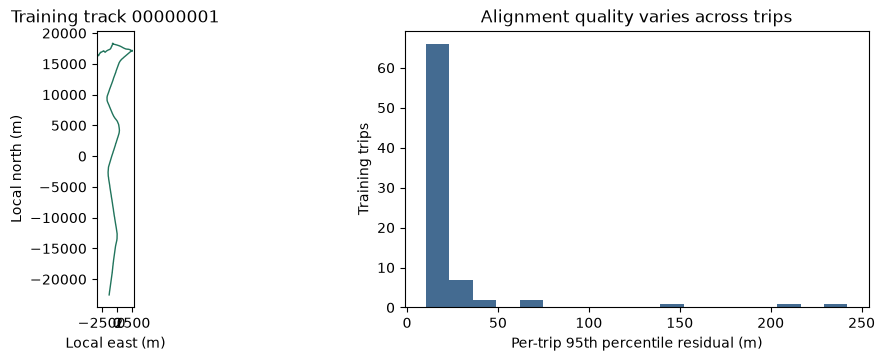

In [8]:
first_csv = CLEAN / "train" / (example.name + ".csv")
preview = pd.read_csv(first_csv, nrows=DEFAULT_K)
print("First observation and its candidate rows:", first_csv.relative_to(ROOT))
display(
    preview[
        [
            "observation",
            "candidate_rank",
            "candidate_arc_id",
            "reference_arc_id",
            "is_match",
            "log_distance",
            "incoming_alignment",
            "outgoing_alignment",
            "along_fraction",
        ]
    ].round(3)
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(sample_net.gps[:, 0], sample_net.gps[:, 1], color="#21745c", lw=1)
axes[0].set(
    xlabel="Local east (m)",
    ylabel="Local north (m)",
    title=f"Training track {example.name}",
    aspect="equal",
)
axes[1].hist(
    inventory.loc[inventory.partition == "train", "reference_residual_p95_m"],
    bins="auto",
    color="#446b91",
)
axes[1].set(
    xlabel="Per-trip 95th percentile residual (m)",
    ylabel="Training trips",
    title="Alignment quality varies across trips",
)
plt.show()

In [9]:
def load_cleaned(split):
    records = []
    # Use the manifest from this run, so older extra files cannot enter the experiment.
    for row in inventory.loc[inventory.partition == split].itertuples():
        frame = pd.read_csv(CLEAN / row.file, dtype={name: "float32" for name in FEATURES})
        n, k = row.observations, row.candidates_per_point
        assert len(frame) == n * k
        assert np.array_equal(frame.observation.to_numpy(), np.repeat(np.arange(n), k))
        ids = frame.candidate_arc_id.to_numpy().reshape(n, k)
        labels = frame.reference_arc_id.to_numpy().reshape(n, k)[:, 0].copy()
        assert np.array_equal(frame.is_match.to_numpy().reshape(n, k), ids == labels[:, None])
        x = np.ascontiguousarray(frame[list(FEATURES)].to_numpy()).reshape(n, k, len(FEATURES))
        assert np.isfinite(x).all()
        records.append(
            dict(
                name=row.trip,
                x=x,
                ids=ids,
                truth=labels,
                edges=frame[["from_node", "to_node"]].to_numpy().reshape(n, k, 2),
                residual=frame.reference_residual_m.to_numpy()[::k].copy(),
            )
        )
    return records


train = load_cleaned("train")
test = load_cleaned("student_test")
print(
    f"Reopened {len(train)} training and {len(test)} student-test CSVs. Example tensor: {train[0]['x'].shape} (observations, candidates, features)."
)

Reopened 80 training and 10 student-test CSVs. Example tensor: (1315, 8, 11) (observations, candidates, features).


## 6. Train and compare five classifiers on whole-trip folds

The binary target asks whether a candidate equals the derived reference arc. For fitting, sample up to 256 covered observations per trip and keep all candidate rows for each sampled observation. For validation, keep all observations, including candidate misses. Use five shuffled **GroupKFold** splits, grouped by trip with seed 41. The same folds and fitting rows are shared across models.

A model scores each candidate independently. Its positive-class probabilities are clipped, converted to log odds, and normalised within each observation. Top-1 is the fraction of aligned arcs matched by the highest-scoring candidate. Calculate arc macro F1 inside each trip, then give trips equal weight. Log loss is conditional on candidate coverage.

In [10]:
def training_rows(trips, cap):
    rng = np.random.default_rng(SEED)
    blocks = []
    targets = []
    for trip in trips:
        y = trip["ids"] == trip["truth"][:, None]
        rows = np.flatnonzero(y.any(axis=1))
        if len(rows) > cap:
            rows = rng.choice(rows, cap, replace=False)
        blocks.append(trip["x"][rows].reshape(-1, len(FEATURES)))
        targets.append(y[rows].ravel())
    return np.concatenate(blocks), np.concatenate(targets)


def probabilities(model, x):
    shape = x.shape[:2]
    pos = model.predict_proba(x.reshape(-1, x.shape[-1]))[:, 1].reshape(shape)
    return softmax(logit(np.clip(pos, 1e-7, 1 - 1e-7)), axis=1)


def evaluation(model, trips):
    rows = []
    for trip in trips:
        x, ids, truth = trip["x"], trip["ids"], trip["truth"]
        start = perf_counter()
        p = (
            probabilities(model, x)
            if model is not None
            else softmax(-np.expm1(x[:, :, 0].astype(float)), axis=1)
        )
        best = p.argmax(axis=1)
        pred = ids[np.arange(len(ids)), best]
        seconds = perf_counter() - start
        actual = ids == truth[:, None]
        covered = actual.any(axis=1)
        prob = (p * actual).sum(axis=1)[covered]
        edges = trip["edges"][np.arange(len(ids)), best]
        # Strict adjacent arc continuity; skips across intermediate arcs count as breaks.
        connected = (pred[1:] == pred[:-1]) | (edges[:-1, 1] == edges[1:, 0])
        pr, re, f1, _ = precision_recall_fscore_support(
            truth, pred, average="macro", zero_division=0
        )
        rows.append(
            dict(
                trip=trip["name"],
                n=len(ids),
                top1=float(np.mean(pred == truth)),
                precision=pr,
                recall=re,
                macro_f1=f1,
                covered=int(covered.sum()),
                log_loss=float(-np.log(np.maximum(prob, 1e-300)).mean()) if len(prob) else None,
                continuity=float(connected.mean()) if len(connected) else None,
                score_seconds=seconds,
            )
        )
    return rows


def summary(rows):
    return {
        k: float(np.mean([r[k] for r in rows if r[k] is not None]))
        for k in (
            "top1",
            "macro_f1",
            "log_loss",
            "continuity",
            "score_seconds",
            "precision",
            "recall",
        )
    }


def fit_evaluate(template, fit_data, trips):
    begin = perf_counter()
    model = clone(template).fit(*fit_data)
    elapsed = perf_counter() - begin
    return model, evaluation(model, trips), elapsed

In [11]:
models = {
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)),
    "naive_bayes": GaussianNB(),
    "decision_tree": DecisionTreeClassifier(
        min_samples_leaf=32, max_depth=12, random_state=SEED
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=32, min_samples_leaf=8, max_depth=18, n_jobs=2, random_state=SEED
    ),
    "boosting": HistGradientBoostingClassifier(
        max_iter=100, early_stopping=False, random_state=SEED
    ),
}
splitter = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = []
manifest = []
for fold, (fit_idx, val_idx) in enumerate(
    splitter.split(train, groups=[t["name"] for t in train])
):
    fit_trips = [train[i] for i in fit_idx]
    validation = [train[i] for i in val_idx]
    assert {t["name"] for t in fit_trips}.isdisjoint(t["name"] for t in validation)
    folds.append((training_rows(fit_trips, CAP), validation))
    manifest.extend({"trip": t["name"], "fold": fold} for t in validation)
fold_table = pd.DataFrame(manifest)
fold_table.to_csv(OUT / "folds.csv", index=False)
display(fold_table.groupby("fold").size().rename("validation_trips").to_frame())
all_fit = training_rows(train, CAP)
print(f"Final fit matrix: {all_fit[0].shape}; {all_fit[1].sum():,} positive candidate labels")
display(
    pd.DataFrame([{"model": key, "estimator": str(value)} for key, value in models.items()])
)

,validation_trips
fold,
0,16
1,16
2,16
3,16
4,16


Final fit matrix: (163840, 11); 20,480 positive candidate labels


,model,estimator
0,logistic,"Pipeline(steps=[('standardscaler', StandardSca..."
1,naive_bayes,GaussianNB()
2,decision_tree,"DecisionTreeClassifier(max_depth=12, min_sampl..."
3,extra_trees,"ExtraTreesClassifier(max_depth=18, min_samples..."
4,boosting,HistGradientBoostingClassifier(early_stopping=...


nearest         CV Top-1 54.81%   student-test Top-1 55.86%


logistic        CV Top-1 83.71%   student-test Top-1 85.43%


naive_bayes     CV Top-1 83.57%   student-test Top-1 85.46%


decision_tree   CV Top-1 86.19%   student-test Top-1 88.71%


extra_trees     CV Top-1 86.36%   student-test Top-1 88.47%


boosting        CV Top-1 86.98%   student-test Top-1 89.41%


,cv_top1,cv_macro_f1,top1,macro_f1,log_loss,train_seconds
model,,,,,,
nearest,0.5481,0.3611,0.5586,0.3638,1.1580,0.0000
logistic,0.8371,0.6911,0.8543,0.6892,0.4615,0.0684
naive_bayes,0.8357,0.7029,0.8546,0.7054,0.7976,0.0206
decision_tree,0.8619,0.7676,0.8871,0.7905,0.5758,1.3853
extra_trees,0.8636,0.7679,0.8847,0.7755,0.3456,0.8309
boosting,0.8698,0.7889,0.8941,0.8048,0.3343,0.5985


Family selected by grouped CV: boosting


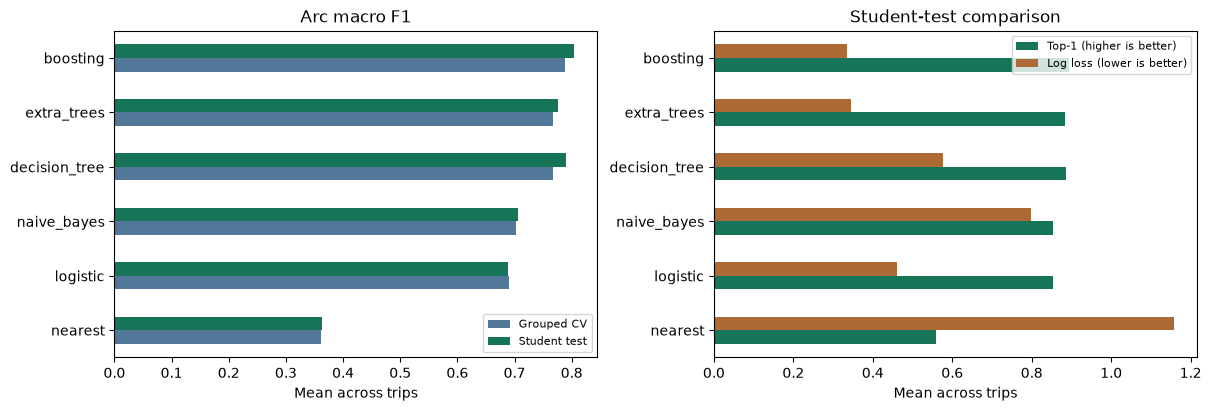

In [12]:
comparisons = []
detail = []


def compare(name, estimator):
    cv_rows = []
    for fold, (fit, validation) in enumerate(folds):
        rows = (
            evaluation(None, validation)
            if estimator is None
            else fit_evaluate(estimator, fit, validation)[1]
        )
        cv_rows.extend(rows)
        detail.extend(dict(model=name, partition="cv", fold=fold, **row) for row in rows)
    if estimator is None:
        fitted = None
        test_rows = evaluation(None, test)
        elapsed = 0.0
    else:
        fitted, test_rows, elapsed = fit_evaluate(estimator, all_fit, test)
    detail.extend(
        dict(model=name, partition="student_test", fold=None, **row) for row in test_rows
    )
    training = summary(evaluation(fitted, train))
    cv = summary(cv_rows)
    record = dict(
        model=name,
        train_top1=training["top1"],
        train_macro_f1=training["macro_f1"],
        cv_top1=cv["top1"],
        cv_macro_f1=cv["macro_f1"],
        train_seconds=elapsed,
        **summary(test_rows),
    )
    comparisons.append(record)
    print(
        f"{name:15} CV Top-1 {cv['top1']:.2%}   student-test Top-1 {record['top1']:.2%}",
        flush=True,
    )
    return fitted


compare("nearest", None)
for name, estimator in models.items():
    compare(name, estimator)
comparison = pd.DataFrame(comparisons).set_index("model")
winner = comparison.loc[list(models), "cv_top1"].idxmax()
display(
    comparison[
        ["cv_top1", "cv_macro_f1", "top1", "macro_f1", "log_loss", "train_seconds"]
    ].round(4)
)
print("Family selected by grouped CV:", winner)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
comparison[["cv_macro_f1", "macro_f1"]].rename(
    columns={"cv_macro_f1": "Grouped CV", "macro_f1": "Student test"}
).plot.barh(ax=axes[0], color=["#527799", "#167458"])
comparison[["top1", "log_loss"]].rename(
    columns={"top1": "Top-1 (higher is better)", "log_loss": "Log loss (lower is better)"}
).plot.barh(ax=axes[1], color=["#167458", "#ac6b36"])
axes[0].set(title="Arc macro F1", xlabel="Mean across trips", ylabel="")
axes[1].set(title="Student-test comparison", xlabel="Mean across trips", ylabel="")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

## 7. Tune the selected family, refit and save

Use a six-trial Bayesian search over one parameter of the CV-winning family. Evaluate the two ends and the middle of its search grid first. A Gaussian process with a Matérn kernel then picks the remaining trial points by expected improvement. Refit the best setting on samples from all training trips. Retain the original configuration if its CV score is higher. The ten student-test trips supply development comparisons. Only grouped training CV determines selection.

In [13]:
search_spaces = {
    "boosting": ("learning_rate", np.geomspace(0.025, 0.3, 33)),
    "logistic": ("logisticregression__C", np.geomspace(0.01, 100, 33)),
    "naive_bayes": ("var_smoothing", np.geomspace(1e-12, 1e-3, 33)),
    "extra_trees": ("min_samples_leaf", np.arange(2, 35)),
    "decision_tree": ("min_samples_leaf", np.arange(4, 100, 3)),
}
parameter, grid = search_spaces[winner]
positions = np.linspace(0, 1, len(grid))[:, None]
tested = []
scores = []
history = []
for trial in range(6):
    if trial < 3:
        idx = [0, len(grid) // 2, len(grid) - 1][trial]
    else:
        gp = GaussianProcessRegressor(
            kernel=Matern(length_scale=0.25, nu=2.5),
            normalize_y=True,
            alpha=1e-5,
            optimizer=None,
        ).fit(positions[tested], scores)
        mean, std = gp.predict(positions, return_std=True)
        gain = mean - max(scores)
        z = gain / np.maximum(std, 1e-12)
        acquisition = gain * norm.cdf(z) + std * norm.pdf(z)
        acquisition[tested] = -np.inf
        idx = int(acquisition.argmax())
    value = grid[idx].item()
    estimator = clone(models[winner]).set_params(**{parameter: value})
    start = perf_counter()
    rows = [r for fit, valid in folds for r in fit_evaluate(estimator, fit, valid)[1]]
    metrics = summary(rows)
    tested.append(idx)
    scores.append(metrics["top1"])
    history.append(
        dict(
            trial=trial + 1,
            family=winner,
            parameter=parameter,
            value=value,
            cv_top1=metrics["top1"],
            cv_macro_f1=metrics["macro_f1"],
            seconds=perf_counter() - start,
        )
    )
trials = pd.DataFrame(history)
trials.to_csv(OUT / "bayesian_trials.csv", index=False)
display(trials.round(6))
best = history[int(np.argmax(scores))]
override = {parameter: best["value"]}
tuned = clone(models[winner]).set_params(**override)
model = compare(winner + "_tuned", tuned)
if best["cv_top1"] < comparison.loc[winner, "cv_top1"]:
    override = {}
    model = clone(models[winner]).fit(*all_fit)
bundle = dict(model=model, features=FEATURES, k=DEFAULT_K)
joblib.dump(bundle, OUT / "model.joblib", compress=3)
config = dict(
    family=winner,
    selected=override,
    features=FEATURES,
    seed=SEED,
    observation_cap_per_fit_trip=CAP,
    candidate_count=DEFAULT_K,
    versions=versions,
)
(OUT / "config.json").write_text(json.dumps(config, indent=2))
pd.DataFrame(comparisons).to_csv(OUT / "model_comparison.csv", index=False)
pd.DataFrame(detail).to_csv(OUT / "trip_metrics.csv", index=False)
display(
    pd.DataFrame(comparisons)
    .set_index("model")
    .loc[[winner, winner + "_tuned"], ["cv_top1", "top1", "macro_f1", "log_loss"]]
    .round(6)
)
print("Saved classifier:", type(model).__name__, override)

,trial,family,parameter,value,cv_top1,cv_macro_f1,seconds
0,1,boosting,learning_rate,0.025000,0.867049,0.782339,4.846618
1,2,boosting,learning_rate,0.086603,0.869493,0.788767,4.868324
2,3,boosting,learning_rate,0.300000,0.854287,0.742895,4.533332
3,4,boosting,learning_rate,0.054348,0.869587,0.788615,5.037844
4,5,boosting,learning_rate,0.068605,0.869757,0.789970,5.043795
5,6,boosting,learning_rate,0.039837,0.868705,0.786964,5.073425


boosting_tuned  CV Top-1 86.98%   student-test Top-1 89.30%


,cv_top1,top1,macro_f1,log_loss
model,,,,
boosting,0.869756,0.894065,0.804823,0.334300
boosting_tuned,0.869757,0.893049,0.801618,0.332956


Saved classifier: HistGradientBoostingClassifier {'learning_rate': 0.06860525610098346}


## 8. Reconstruct routes and check the final result

A classifier chooses one candidate at a time. Viterbi decoding finds a sequence of projected directed arcs using classifier emissions and movement costs along reachable roads. Estimate residual scale, plausible speed and time-gap threshold from the training trips. Restart a fragment at a long gap or when no transition is feasible. Backtracking recovers the selected observation arcs and the connecting roads.

In [14]:
def decode_path(net, ids, x, emissions, config, forced_starts=None):
    adjacency = [[] for _ in net.nodes]
    for arc, ((a, b), length) in enumerate(zip(net.arcs, net.length)):
        if length > 0:
            adjacency[a].append((b, length, arc))
    scale = config["distance_scale_m"]

    @lru_cache(maxsize=8192)
    def paths(source, budget):
        distances = {source: 0.0}
        parent = {}
        queue = [(0.0, source)]
        while queue:
            d, node = heapq.heappop(queue)
            if d > distances[node]:
                continue
            for target, length, arc in adjacency[node]:
                cost = d + length
                if cost <= budget and cost < distances.get(target, np.inf):
                    distances[target] = cost
                    parent[target] = (node, arc)
                    heapq.heappush(queue, (cost, target))
        return distances, parent

    dt = np.diff(net.track[:, 2])
    observed = np.linalg.norm(np.diff(net.gps, axis=0), axis=1)
    # Round cache radii upward for reuse; mask distances against the true budget.
    valid_step = (dt > 0) & (dt <= config["gap_s"])
    travel_time = dt
    if forced_starts is not None:
        valid_step = dt > 0
        valid_step[np.asarray(forced_starts[1:], dtype=int) - 1] = False
        travel_time = np.minimum(dt, config["gap_s"])
    bounds = np.maximum(observed, travel_time * config["speed_mps"]) + 3 * scale
    budgets = np.ceil(bounds / scale) * scale
    log_e = np.where(emissions > 0, np.log(np.maximum(emissions, 1e-300)), -np.inf)
    reversal_cost = config.get("reversal_cost", 0.0)
    if config.get("motion_prior", False):
        # Neighbouring feature windows share GPS samples. Temper repeated classifier
        # evidence and retain a direct distance likelihood for the observed point.
        log_e = 0.5 * log_e - np.expm1(x[:, :, 0]) / scale
    values = log_e[0].copy()
    back = np.full(ids.shape, -1, int)
    choice = np.empty(len(ids), int)
    starts = [0]
    along = net.length[ids] * x[:, :, 2]
    edges = net.arcs[ids]

    def trace(start, end, scores):
        choice[end] = scores.argmax()
        for j in range(end, start, -1):
            choice[j - 1] = back[j, choice[j]]

    for i in range(1, len(ids)):
        if valid_step[i - 1]:
            middle = np.array(
                [
                    [paths(a, budgets[i - 1])[0].get(b, np.inf) for b in edges[i, :, 0]]
                    for a in edges[i - 1, :, 1]
                ]
            )
            travel = (net.length[ids[i - 1]] - along[i - 1])[:, None] + middle + along[i]
            offset = along[i][None, :] - along[i - 1][:, None]
            direct = (ids[i - 1, :, None] == ids[i, None, :]) & (offset >= -scale)
            travel = np.where(direct, np.minimum(travel, np.maximum(offset, 0)), travel)
            transition = np.where(
                travel <= bounds[i - 1], -abs(travel - observed[i - 1]) / scale, -np.inf
            )
            if config.get("motion_prior", False):
                reversed_edge = (
                    (edges[i - 1, :, 0, None] == edges[i, None, :, 1])
                    & (edges[i - 1, :, 1, None] == edges[i, None, :, 0])
                )
                transition -= reversal_cost * reversed_edge
            else:
                norm = logsumexp(transition, axis=1, keepdims=True)
                transition -= np.where(np.isfinite(norm), norm, 0)
            scores = values[:, None] + transition
            next_values = scores.max(axis=0) + log_e[i]
            if np.isfinite(next_values).any():
                back[i] = scores.argmax(axis=0)
                values = next_values
                continue
        trace(starts[-1], i - 1, values)
        starts.append(i)
        values = log_e[i].copy()
    trace(starts[-1], len(ids) - 1, values)
    pred = ids[np.arange(len(ids)), choice]
    fragments = []
    anchors = np.zeros(len(ids), dtype=int)
    for begin, end in zip(starts, starts[1:] + [len(ids)]):
        fragment = [int(pred[begin])]
        for i in range(begin + 1, end):
            prev, curr = pred[i - 1 : i + 1]
            if prev == curr and along[i, choice[i]] >= along[i - 1, choice[i - 1]] - scale:
                anchors[i] = len(fragment) - 1
                continue
            source, target = net.arcs[prev, 1], net.arcs[curr, 0]
            parent = paths(source, budgets[i - 1])[1]
            connector = []
            while target != source:
                target, arc = parent[target]
                connector.append(arc)
            fragment.extend(reversed(connector))
            fragment.append(int(curr))
            anchors[i] = len(fragment) - 1
        fragments.append(fragment)
    return pred, fragments, starts, anchors


def align_to_prediction(net, fragments, starts, anchors, radius):
    """Place observations in traversal order on a local window of the inferred path."""
    result = np.empty(len(net.gps), dtype=int)
    for route, first, end in zip(fragments, starts, starts[1:] + [len(result)]):
        route = np.asarray(route)
        width = min(2 * radius + 1, len(route))
        left = np.clip(anchors[first:end] - radius, 0, len(route) - width)
        columns = np.arange(width)
        occurrences = left[:, None] + columns
        distance, _ = projection(net, net.gps[first:end, None], route[occurrences])
        cost = distance[0] ** 2
        back = np.empty(distance.shape, dtype=int)
        for i in range(1, end - first):
            # The left edge only moves forward. A predecessor can be any previous
            # occurrence up to and including the current occurrence.
            limit = np.minimum(columns + left[i] - left[i - 1], width - 1)
            prefix = np.minimum.accumulate(cost)
            best = np.maximum.accumulate(np.where(cost == prefix, columns, 0))
            back[i] = best[limit]
            cost = prefix[limit] + distance[i] ** 2
        col = int(cost.argmin())
        for i in reversed(range(end - first)):
            result[first + i] = route[left[i] + col]
            if i:
                col = back[i, col]
    return result


def decode(net, ids, x, emissions, config):
    pred, fragments, starts, anchors = decode_path(net, ids, x, emissions, config)
    radius = config.get("alignment_radius", 0)
    if radius:
        pred = align_to_prediction(net, fragments, starts, anchors, radius)
    return pred, fragments, starts


def edit(a, b):
    # Vectorised row update for unit insertion, deletion, substitution cost.
    b = np.asarray(b)
    previous = np.arange(len(b) + 1)
    index = previous.copy()
    for i, item in enumerate(a, 1):
        row = np.r_[i, np.minimum(previous[1:] + 1, previous[:-1] + (b != item))]
        previous = np.minimum.accumulate(row - index) + index
    return previous[-1] / max(len(a), len(b), 1)


def collapsed(seq):
    return [k for k, _ in groupby(seq)]

### Select the decoder on whole training trips

Compare the original Viterbi decoder with two changes, individually and together. The motion variant gives half weight to classifier log scores because adjacent feature windows overlap, adds a distance-based GPS score, and penalises direct reversals by their smoothed log odds on fitting trips. Its transition costs reflect the absolute discrepancy between network travel and GPS movement. The alignment variant assigns each observation to a road along the model’s own inferred traversal, minimising squared GPS distance while preserving traversal order. It searches up to eight road occurrences on either side of the Viterbi assignment, including connector roads between observations. Each fragment is aligned independently.

For each validation fold, refit the classifier and estimate decoder scales and reversal frequency using the other four folds. Select the decoder by mean held-out trip Top-1 across the 80 training trips. These folds are also used for classifier tuning, so this is a model-selection score. Both test partitions are excluded from this decision.

Four additional alternatives start from the motion-aware aligned decoder. Test a wider candidate search, time-weighted GPS smoothing, smoothing with distance-spaced observations, and all three together. Smoothing fits a local constant velocity on up to nine samples within a continuous time interval. The sparse decoder retains fragment endpoints and a new observation after a movement of two training residual scales. Long stationary periods therefore contribute fewer repeated votes. Widening evaluates up to 16 roads when additional roads are plausible or the nearest road fits poorly. The final ordered alignment and scoring use every original GPS point. All settings are shared across trips.

In [15]:
def smooth_gps(net, gap):
    """Local linear position estimates. Isolate gaps and preserve constant velocity."""
    gps = net.gps.copy()
    time = net.track[:, 2]
    breaks = np.flatnonzero((np.diff(time) <= 0) | (np.diff(time) > gap)) + 1
    for rows in np.split(np.arange(len(time)), breaks):
        if len(rows) < 3:
            continue
        start, end = rows[0], rows[-1]
        neighbours = rows[:, None] + np.arange(-4, 5)
        valid = (neighbours >= start) & (neighbours <= end)
        neighbours = np.clip(neighbours, start, end)
        offsets = time[neighbours] - time[rows, None]
        bandwidth = 2 * np.median(np.diff(time[rows]))
        weights = np.exp(-0.5 * (offsets / bandwidth) ** 2) * valid
        # Intercept of a weighted linear fit at each observation time.
        t1 = (weights * offsets).sum(axis=1, keepdims=True)
        t2 = (weights * offsets**2).sum(axis=1, keepdims=True)
        intercept = weights * (t2 - t1 * offsets)
        total = intercept.sum(axis=1, keepdims=True)
        stable = total[:, 0] > 1e-12
        weighted_xy = intercept[stable, :, None] * net.gps[neighbours[stable]]
        gps[rows[stable]] = weighted_xy.sum(axis=1) / total[stable]
    return replace(net, gps=gps)


def motion_anchors(net, config):
    """Retain endpoints and spatially distinct observations within each sampling fragment."""
    time = net.track[:, 2]
    intervals = np.diff(time)
    breaks = np.flatnonzero((intervals <= 0) | (intervals > config["gap_s"])) + 1
    keep = []
    forced_starts = []
    for rows in np.split(np.arange(len(time)), breaks):
        forced_starts.append(len(keep))
        last = rows[0]
        keep.append(last)
        for i in rows[1:-1]:
            if np.linalg.norm(net.gps[i] - net.gps[last]) >= 2 * config["distance_scale_m"]:
                keep.append(i)
                last = i
        if rows[-1] != last:
            keep.append(rows[-1])
    return np.asarray(keep), np.asarray(forced_starts)


def search_route(net, model, k, config):
    search_net = smooth_gps(net, config["gap_s"]) if config.get("smooth_gps") else net
    width = 2 * k if config.get("wide_search") else k
    ids, x = features(search_net, width)
    scores = probabilities(model, x)
    if config.get("wide_search") and ids.shape[1] > k:
        # Keep all original candidates. Admit farther roads when the closest road
        # fits poorly or the extra road is within one spatial error scale of it.
        dist = np.expm1(x[:, :, 0])
        scale = config["distance_scale_m"]
        plausible = (dist[:, :1] > scale) | (dist[:, k:] <= dist[:, :1] + scale)
        scores[:, k:] = np.where(plausible, scores[:, k:], 0)
    if config.get("use_anchors"):
        keep, forced = motion_anchors(search_net, config)
        sparse = replace(search_net, track=search_net.track[keep], gps=search_net.gps[keep])
        _, fragments, starts, anchors = decode_path(
            sparse, ids[keep], x[keep], scores[keep], config, forced_starts=forced
        )
        # Map retained path positions back to original sample indices within each
        # fragment. The final ordered alignment below uses every original GPS point.
        starts = keep[starts].tolist()
        dense = np.zeros(len(net.gps), dtype=int)
        for first, end in zip(starts, starts[1:] + [len(dense)]):
            inside = (keep >= first) & (keep < end)
            positions = np.interp(np.arange(first, end), keep[inside], anchors[inside])
            dense[first:end] = np.rint(positions).astype(int)
        path = align_to_prediction(net, fragments, starts, dense, config.get("alignment_radius") or k)
        return path, fragments, starts
    path, fragments, starts, anchors = decode_path(search_net, ids, x, scores, config)
    radius = config.get("alignment_radius", 0)
    if radius:
        path = align_to_prediction(net, fragments, starts, anchors, radius)
    return path, fragments, starts

In [16]:
def trip_motion_samples(net, record):
    dt = np.diff(net.track[:, 2])
    valid = dt > 0
    speed = np.linalg.norm(np.diff(net.gps, axis=0), axis=1)[valid] / dt[valid]
    truth = record["truth"]
    change = truth[1:] != truth[:-1]
    before = net.arcs[truth[:-1][change]]
    after = net.arcs[truth[1:][change]]
    reverse = np.all(before == after[:, ::-1], axis=1)
    return record["residual"], dt[valid], speed, int(reverse.sum()), len(reverse)


def fit_decoder(samples):
    residual, dt, speed, reversals, changes = zip(*samples)
    reverse = sum(reversals)
    # Smoothed log odds of a direct reversal among changes of road.
    odds = (sum(changes) - reverse + 1) / (reverse + 1)
    return dict(
        distance_scale_m=float(np.quantile(np.concatenate(residual), 0.75)),
        gap_s=float(np.quantile(np.concatenate(dt), 0.995)),
        speed_mps=float(np.quantile(np.concatenate(speed), 0.99)),
        reversal_cost=float(max(0, np.log(odds))),
    )


motion_samples = {
    t["name"]: trip_motion_samples(read_trip(DATA / "train" / t["name"]), t)
    for t in train
}
# One baseline and three prespecified alternatives. Choose using only training trips.
variants = {
    "original": (False, False),
    "aligned": (False, True),
    "motion": (True, False),
    "motion_aligned": (True, True),
}
search_variants = {
    "wider": {"wide_search": True},
    "smoothed": {"smooth_gps": True},
    "smoothed_anchors": {"smooth_gps": True, "use_anchors": True},
    "smoothed_anchors_wider": {"smooth_gps": True, "use_anchors": True, "wide_search": True},
}
validation_rows = []
for fold, (fit, validation) in enumerate(folds):
    held_out = {t["name"] for t in validation}
    settings = fit_decoder([s for name, s in motion_samples.items() if name not in held_out])
    fold_model = clone(model).fit(*fit)
    for trip in validation:
        net = read_trip(DATA / "train" / trip["name"])
        ids, x, truth = (trip[key] for key in ("ids", "x", "truth"))
        scores = probabilities(fold_model, x)
        for use_motion in (False, True):
            raw, segments, starts, anchors = decode_path(
                net, ids, x, scores, dict(settings, motion_prior=use_motion)
            )
            aligned = align_to_prediction(net, segments, starts, anchors, DEFAULT_K)
            for name, (motion, realign) in variants.items():
                if motion != use_motion:
                    continue
                pred = aligned if realign else raw
                validation_rows.append(dict(
                    fold=fold, trip=trip["name"], method=name, n=len(truth),
                    correct=int(np.sum(pred == truth)), top1=float(np.mean(pred == truth)),
                    macro_f1=f1_score(truth, pred, average="macro", zero_division=0),
                ))
        for name, extra in search_variants.items():
            settings_for_trip = dict(settings, motion_prior=True, alignment_radius=DEFAULT_K, **extra)
            pred, _, _ = search_route(net, fold_model, DEFAULT_K, settings_for_trip)
            validation_rows.append(dict(
                fold=fold, trip=trip["name"], method=name, n=len(truth),
                correct=int(np.sum(pred == truth)), top1=float(np.mean(pred == truth)),
                macro_f1=f1_score(truth, pred, average="macro", zero_division=0),
            ))
    print(f"Scored held-out training fold {fold + 1}/{len(folds)}", flush=True)

validation_scores = pd.DataFrame(validation_rows)
assert (validation_scores.groupby("method").trip.nunique() == len(train)).all()
validation_scores.to_csv(OUT / "decoder_validation.csv", index=False)
leaderboard = validation_scores.groupby("method", sort=False)[["top1", "macro_f1"]].mean()
selected_decoder = leaderboard.top1.idxmax()
use_motion, realign = variants.get(selected_decoder, (True, True))
decoder_config = dict(
    fit_decoder(list(motion_samples.values())),
    motion_prior=use_motion, alignment_radius=DEFAULT_K if realign else 0,
    **search_variants.get(selected_decoder, {}),
)
(OUT / "decoder.json").write_text(json.dumps(decoder_config, indent=2))
display(leaderboard)
print("Frozen decoder:", selected_decoder, decoder_config)

Scored held-out training fold 1/5


Scored held-out training fold 2/5


Scored held-out training fold 3/5


Scored held-out training fold 4/5


Scored held-out training fold 5/5


,top1,macro_f1
method,,
original,0.862179,0.867479
aligned,0.899550,0.905176
motion,0.869221,0.880743
motion_aligned,0.903789,0.910962
wider,0.906726,0.917822
smoothed,0.935127,0.943518
smoothed_anchors,0.948056,0.954490
smoothed_anchors_wider,0.949374,0.957274


Frozen decoder: smoothed_anchors_wider {'distance_scale_m': 10.915663698419326, 'gap_s': 6.0, 'speed_mps': 46.350712478527015, 'reversal_cost': 9.553398019955731, 'motion_prior': True, 'alignment_radius': 8, 'smooth_gps': True, 'use_anchors': True, 'wide_search': True}


### Evaluate the frozen model on both test sets

Compare the frozen decoder and the original decoder on identical inputs using the teacher’s original scoring rule. Each trip has equal weight for Top-1 and arc macro F1. Pooled Top-1 weights every observation equally. The evaluator section runs when the teacher’s separate `evaluator_test/` folder is present beside `Student folder/`. The historical scores on these test sets were previously seen, so an independent new set would be needed for a fully blind assessment.

In [17]:
saved = joblib.load(OUT / "model.joblib")
frozen = json.loads((OUT / "decoder.json").read_text())
original = dict(frozen, motion_prior=False, alignment_radius=0)
evaluation_inputs = {
    "student_test": [(d, d) for d in trips["student_test"]]
}
evaluator_root = DATA.parent / "evaluator_test"
if evaluator_root.is_dir():
    cleaned_evaluator = CLEAN / "evaluator_test"
    raw_trips = sorted(p for p in evaluator_root.iterdir() if p.is_dir())
    used_ids = {p.name for split in PARTITIONS for p in trips[split]}
    assert used_ids.isdisjoint(p.name for p in raw_trips)
    # Prefer the demo's prepared inputs. The original directory supplies scoring labels.
    evaluation_inputs["evaluator_test"] = [
        (cleaned_evaluator / p.name if cleaned_evaluator.is_dir() else p, p) for p in raw_trips
    ]

route_rows = []
for split, pairs in evaluation_inputs.items():
    for inputs, reference_dir in pairs:
        net = read_trip(inputs)
        ids, x = features(net, saved["k"])
        emission = probabilities(saved["model"], x)
        raw = ids[np.arange(len(ids)), emission.argmax(axis=1)]
        outcomes = [("classifier", raw, collapsed(raw))]
        previous = dict(original, motion_prior=True, alignment_radius=DEFAULT_K)
        for name, settings in [
            ("original_viterbi", original), ("previous_viterbi", previous), ("viterbi", frozen)
        ]:
            if name == "viterbi":
                pred, segments, starts = search_route(net, saved["model"], saved["k"], settings)
            else:
                pred, segments, starts = decode(net, ids, x, emission, settings)
            sequence = []
            for segment in segments:
                if sequence:
                    sequence.append(-1)
                sequence.extend(collapsed(segment))
            outcomes.append((name, pred, sequence))
        # Reference files are opened only after all predictions for this trip are complete.
        route = read_reference(reference_dir, net)
        truth = align(net, route)
        for method, obs, sequence in outcomes:
            match = obs == truth
            route_rows.append(dict(
                partition=split, trip=inputs.name, method=method, n=len(obs),
                correct=int(match.sum()), top1=match.mean(),
                macro_f1=f1_score(truth, obs, average="macro", zero_division=0),
                normalized_edit=edit(sequence, collapsed(route)),
            ))
routes = pd.DataFrame(route_rows)
routes.to_csv(OUT / "route_comparison.csv", index=False)
by_method = routes.groupby(["partition", "method"])
summary_scores = by_method[["top1", "macro_f1", "normalized_edit"]].mean()
summary_scores["pooled_top1"] = by_method.correct.sum() / by_method.n.sum()
display(summary_scores.round(5))

top1  macro_f1  normalized_edit  \
partition      method                                                 
evaluator_test classifier        0.91818   0.79930          0.35642   
               original_viterbi  0.90834   0.85604          0.21349   
               previous_viterbi  0.94162   0.90489          0.18687   
               viterbi           0.98901   0.98819          0.02378   
student_test   classifier        0.89305   0.80162          0.40684   
               original_viterbi  0.91222   0.90384          0.17169   
               previous_viterbi  0.93085   0.93175          0.15030   
               viterbi           0.98009   0.98214          0.03840   

                                 pooled_top1  
partition      method                         
evaluator_test classifier            0.87806  
               original_viterbi      0.81310  
               previous_viterbi      0.89382  
               viterbi               0.99263  
student_test   classifier            0.87672  
               original_viterbi      0.89494  
               previous_viterbi      0.92510  
               viterbi               0.98518

### Reading the evidence

Use the **inventory** to check candidate coverage and raw-data quality. Open any **trip CSV** and filter by observation to inspect all competing arcs, feature values and the aligned target. Use **folds.csv** to verify whole-trip separation, **model_comparison.csv** to compare the five classifiers and **bayesian_trials.csv** to trace model selection. **route_comparison.csv** shows the effect of decoding on each trip. Mean trip Top-1 gives each journey equal weight. Pooled Top-1 gives each observation equal weight. The ordered reference route supplies a separate sequence check through normalised edit distance, where lower is better. **decoder_validation.csv** records every held-out training trip for each decoder variant. The final route table includes both the original and selected decoder.